<a href="https://colab.research.google.com/github/skanrrking/DiabetesPrediction/blob/main/Logistic_Regression_Diabetes_Checkup_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ============================================
# PART 1: DIABETES RISK PREDICTION MODEL
# UCI CDC Diabetes Health Indicators (ID 891)
# ============================================

!pip install -q ucimlrepo

import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    accuracy_score,
    recall_score,
    precision_score
)

# 1. FETCH DATASET
dataset = fetch_ucirepo(id=891)

X = dataset.data.features.copy()
y = dataset.data.targets["Diabetes_binary"].astype(int)

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Target:", y.shape)
print("\nClass distribution:")
print(y.value_counts(normalize=True).sort_index().rename(
    index={0: "No diabetes (0)", 1: "Prediabetes or diabetes (1)"}
).map(lambda x: f"{x:.2%}"))

assert len(X) == 253680, f"Unexpected row count: {len(X)}"
assert X.shape[1] == 21, f"Expected 21 features, got {X.shape[1]}"

# 2. TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\nTraining samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# 3. TRAIN RANDOM FOREST MODEL
diabetes_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("\nTraining model...")
diabetes_model.fit(X_train, y_train)
print("Training complete!")

# 4. EVALUATE RANDOM FOREST
y_pred = diabetes_model.predict(X_test)
y_prob = diabetes_model.predict_proba(X_test)[:, 1]

print("\n========== RANDOM FOREST ==========")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No diabetes (0)", "Prediabetes or diabetes (1)"],
    zero_division=0,
    digits=4
))

model_accuracy = accuracy_score(y_test, y_pred)
model_recall = recall_score(y_test, y_pred, pos_label=1)
model_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)
model_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {model_accuracy:.4f}")
print(f"Recall (Class 1): {model_recall:.4f}")
print(f"Precision (Class 1): {model_precision:.4f}")
print(f"ROC-AUC: {model_auc:.4f}")

# 5. BASELINE: ALWAYS PREDICT NO DIABETES
baseline_pred = [0] * len(y_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_recall = recall_score(
    y_test, baseline_pred, pos_label=1, zero_division=0
)
baseline_precision = precision_score(
    y_test, baseline_pred, pos_label=1, zero_division=0
)

print("\n========== BASELINE MODEL ==========")
print("Prediction: Always no diabetes (class 0)")
print(f"Accuracy:  {baseline_accuracy:.4f} ({baseline_accuracy:.2%})")
print(f"Recall (Class 1): {baseline_recall:.4f}")
print(f"Precision (Class 1): {baseline_precision:.4f}")

# 6. SIDE-BY-SIDE COMPARISON
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Recall (Class 1)", "Precision (Class 1)"],
    "Always Predict No Diabetes": [
        baseline_accuracy, baseline_recall, baseline_precision
    ],
    "Random Forest": [
        model_accuracy, model_recall, model_precision
    ]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison.to_string(index=False, formatters={
    "Always Predict No Diabetes": "{:.4f}".format,
    "Random Forest": "{:.4f}".format
}))

print("\nModel saved in variable: diabetes_model")


Dataset loaded successfully!
Features: (253680, 21)
Target: (253680,)

Class distribution:
Diabetes_binary
No diabetes (0)                86.07%
Prediabetes or diabetes (1)    13.93%
Name: proportion, dtype: object

Training samples: 202944
Testing samples: 50736

Training model...
Training complete!

========== RANDOM FOREST ==========
                             precision    recall  f1-score   support

            No diabetes (0)     0.8764    0.9705    0.9211     43667
Prediabetes or diabetes (1)     0.4591    0.1546    0.2313      7069

                   accuracy                         0.8568     50736
                  macro avg     0.6677    0.5626    0.5762     50736
               weighted avg     0.8183    0.8568    0.8250     50736

Accuracy:  0.8568
Recall (Class 1): 0.1546
Precision (Class 1): 0.4591
ROC-AUC: 0.7947

========== BASELINE MODEL ==========
Prediction: Always no diabetes (class 0)
Accuracy:  0.8607 (86.07%)
Recall (Class 1): 0.0000
Precision (Class 1): 0.000

In [ ]:

# ============================================
# PART 2: COMPARE THREE MACHINE LEARNING MODELS
# Random Forest vs. Logistic Regression vs. XGBoost
# ============================================

!pip install -q xgboost

import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from xgboost import XGBClassifier

# 1. Calculate class imbalance from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print(f"Training class 0: {negative_count:,}")
print(f"Training class 1: {positive_count:,}")
print(f"XGBoost class weight ratio: {scale_pos_weight:.3f}")

# 2. Create Logistic Regression model
# StandardScaler standardizes features for Logistic Regression.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

# 3. Create XGBoost model
xgboost_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# 4. Train the two new models
print("\nTraining Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Training XGBoost...")
xgboost_model.fit(X_train, y_train)

print("Training complete!")

# 5. Compare all three trained models
models = {
    "Random Forest": diabetes_model,
    "Logistic Regression": logistic_model,
    "XGBoost": xgboost_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Class 1)": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Recall (Class 1)": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1-score (Class 1)": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

# 6. Add baseline: always predict no diabetes (class 0)
baseline_predictions = [0] * len(y_test)

results.append({
    "Model": "Baseline (always class 0)",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision (Class 1)": precision_score(
        y_test, baseline_predictions, pos_label=1, zero_division=0
    ),
    "Recall (Class 1)": recall_score(
        y_test, baseline_predictions, pos_label=1, zero_division=0
    ),
    "F1-score (Class 1)": f1_score(
        y_test, baseline_predictions, pos_label=1, zero_division=0
    ),
    # Constant predictions cannot rank positive vs. negative cases.
    "ROC-AUC": float("nan")
})

# 7. Display comparison, highest class 1 recall first
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Recall (Class 1)",
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")
print(results_df.to_string(
    index=False,
    formatters={
        col: "{:.4f}".format
        for col in results_df.columns
        if col != "Model"
    }
))

# 8. Identify the best model for each key metric
print("\n========== BEST MODEL BY METRIC ==========")

for metric in [
    "Accuracy",
    "Precision (Class 1)",
    "Recall (Class 1)",
    "F1-score (Class 1)",
    "ROC-AUC"
]:
    valid_results = results_df.dropna(subset=[metric])
    best_row = valid_results.loc[valid_results[metric].idxmax()]
    print(f"{metric}: {best_row['Model']} ({best_row[metric]:.4f})")

print("\nModels available for future cells:")
print("- diabetes_model (Random Forest)")
print("- logistic_model (Logistic Regression)")
print("- xgboost_model (XGBoost)")


Training class 0: 174,667
Training class 1: 28,277
XGBoost class weight ratio: 6.177

Training Logistic Regression...
Training XGBoost...
Training complete!

========== MODEL COMPARISON ==========
                    Model Accuracy Precision (Class 1) Recall (Class 1) F1-score (Class 1) ROC-AUC
                  XGBoost   0.7229              0.3079           0.7926             0.4435  0.8272
      Logistic Regression   0.7315              0.3107           0.7611             0.4413  0.8196
            Random Forest   0.8568              0.4591           0.1546             0.2313  0.7947
Baseline (always class 0)   0.8607              0.0000           0.0000             0.0000     NaN

========== BEST MODEL BY METRIC ==========
Accuracy: Baseline (always class 0) (0.8607)
Precision (Class 1): Random Forest (0.4591)
Recall (Class 1): XGBoost (0.7926)
F1-score (Class 1): XGBoost (0.4435)
ROC-AUC: XGBoost (0.8272)

Models available for future cells:
- diabetes_model (Random Forest)
- logist

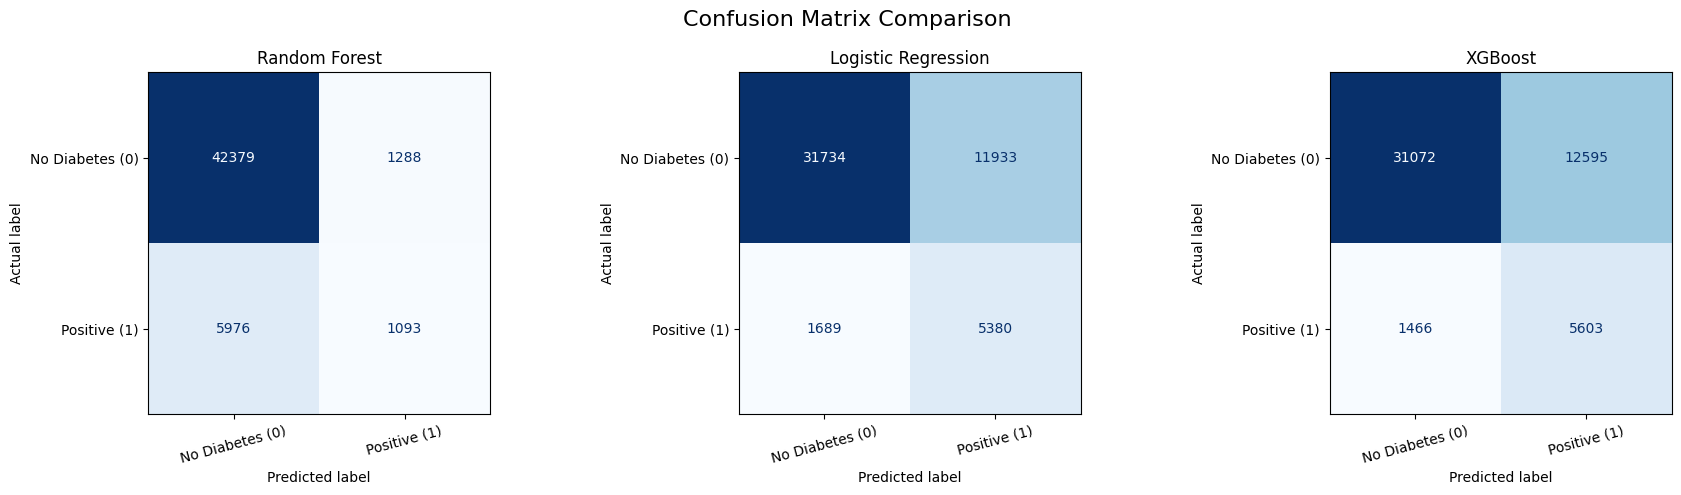


========== PRECISION & RECALL ==========
              Model Precision (Class 1) Recall (Class 1)
      Random Forest              0.4591           0.1546
Logistic Regression              0.3107           0.7611
            XGBoost              0.3079           0.7926


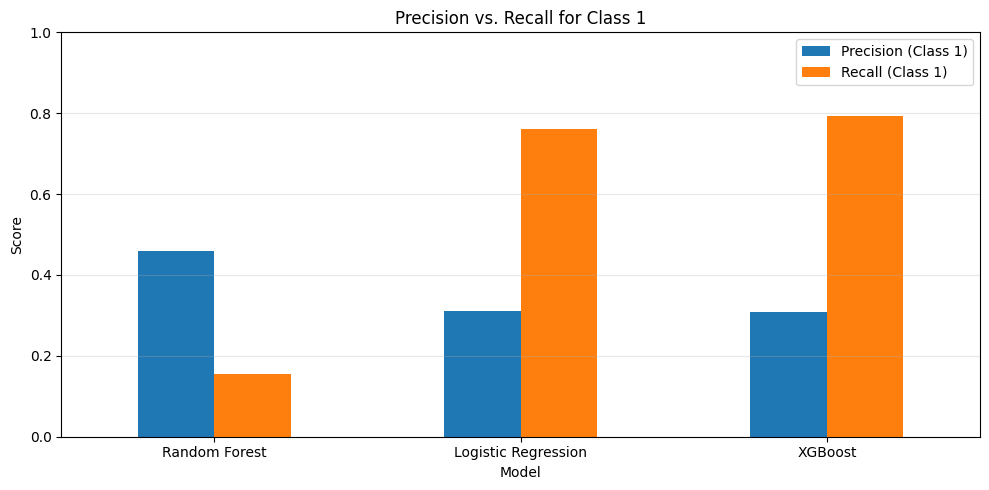

In [ ]:

# ============================================
# PART 3: CONFUSION MATRICES + PRECISION/RECALL
# ============================================

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score
)

# The three trained models from Part 1 and Part 2
models = {
    "Random Forest": diabetes_model,
    "Logistic Regression": logistic_model,
    "XGBoost": xgboost_model
}

# 1. Display confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Diabetes (0)", "Positive (1)"]
    )

    display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.show()

# 2. Compare precision and recall for class 1
comparison = []

for name, model in models.items():
    predictions = model.predict(X_test)

    precision = precision_score(
        y_test, predictions, pos_label=1, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    comparison.append({
        "Model": name,
        "Precision (Class 1)": precision,
        "Recall (Class 1)": recall
    })

comparison_df = pd.DataFrame(comparison)

print("\n========== PRECISION & RECALL ==========")
print(comparison_df.to_string(
    index=False,
    formatters={
        "Precision (Class 1)": "{:.4f}".format,
        "Recall (Class 1)": "{:.4f}".format
    }
))

# 3. Bar chart comparing precision and recall
comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Precision vs. Recall for Class 1")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


MODEL COMPARISON
          Model  Number of Questions  Recall  Precision    TN    FP   FN   TP
    Tier 1 only                   12  0.7384     0.2972 31325 12342 1849 5220
Tier 1 + Tier 2                   17  0.7630     0.3104 31685 11982 1675 5394


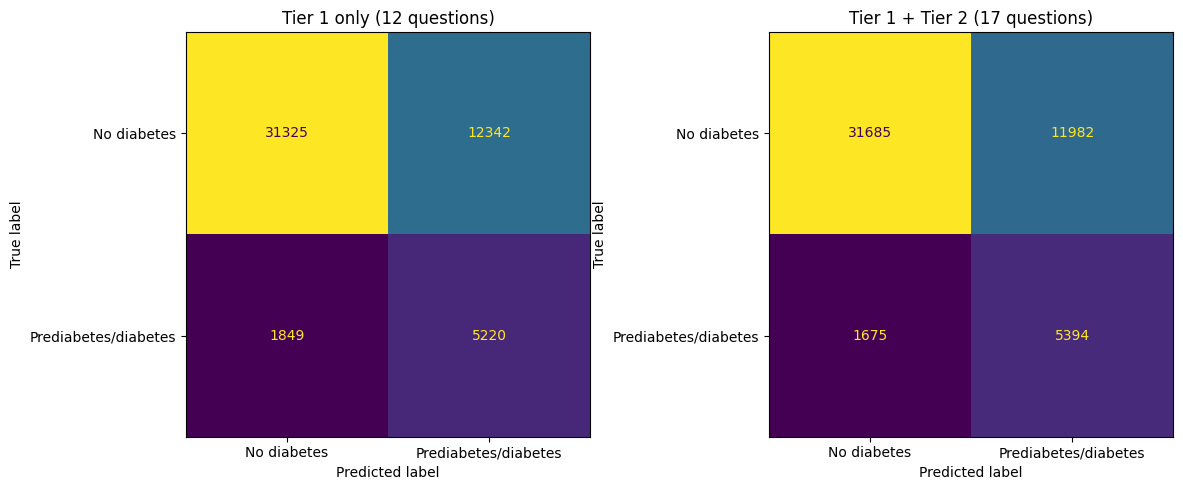

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    recall_score,
    precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Tier 1: self-reported health and lifestyle questions
tier1_features = [
    "BMI",
    "Smoker",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Age",
    "Sex"
]

# Tier 2: medical history and clinical information
tier2_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Stroke",
    "HeartDiseaseorAttack"
]

feature_sets = {
    "Tier 1 only": tier1_features,
    "Tier 1 + Tier 2": tier1_features + tier2_features
}

results = []
predictions_by_model = {}

for name, features in feature_sets.items():

    # Create the Logistic Regression model
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    # Train using only the selected questions
    model.fit(X_train[features], y_train)

    # Predict on the test data
    predictions = model.predict(X_test[features])

    # Calculate the confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    # Save predictions for the confusion matrix plots
    predictions_by_model[name] = predictions

    # Save evaluation metrics
    results.append({
        "Model": name,
        "Number of Questions": len(features),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

# Display results
results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, features) in zip(axes, feature_sets.items()):
    cm = confusion_matrix(
        y_test,
        predictions_by_model[name],
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No diabetes", "Prediabetes/diabetes"]
    )

    display.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{name} ({len(features)} questions)")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# Get the Logistic Regression model from the pipeline
lr = logistic_model.named_steps["logisticregression"]

# Use all features from the original model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lr.coef_[0],
    "Absolute Importance": abs(lr.coef_[0])
})

# Rank features from most to least important
importance_df = importance_df.sort_values(
    by="Absolute Importance",
    ascending=False
)

print(importance_df.round(4).to_string(index=False))


             Feature  Coefficient  Absolute Importance
             GenHlth       0.6188               0.6188
                 BMI       0.4906               0.4906
                 Age       0.4574               0.4574
              HighBP       0.3643               0.3643
            HighChol       0.2873               0.2873
           CholCheck       0.2477               0.2477
   HvyAlcoholConsump      -0.1730               0.1730
                 Sex       0.1392               0.1392
              Income      -0.1193               0.1193
HeartDiseaseorAttack       0.0730               0.0730
            PhysHlth      -0.0584               0.0584
           Education      -0.0374               0.0374
            DiffWalk       0.0374               0.0374
              Stroke       0.0372               0.0372
              Fruits      -0.0348               0.0348
            MentHlth      -0.0323               0.0323
        PhysActivity      -0.0194               0.0194
       Any

MODEL COMPARISON
         Model  Number of Features  Precision  Recall  ROC-AUC    TN    FP   FN   TP
Top 3 Features                   3     0.2938  0.7343   0.7952 31192 12475 1878 5191
Top 5 Features                   5     0.3030  0.7608   0.8130 31295 12372 1691 5378
Top 7 Features                   7     0.3052  0.7599   0.8158 31439 12228 1697 5372
Top 9 Features                   9     0.3086  0.7650   0.8184 31550 12117 1661 5408


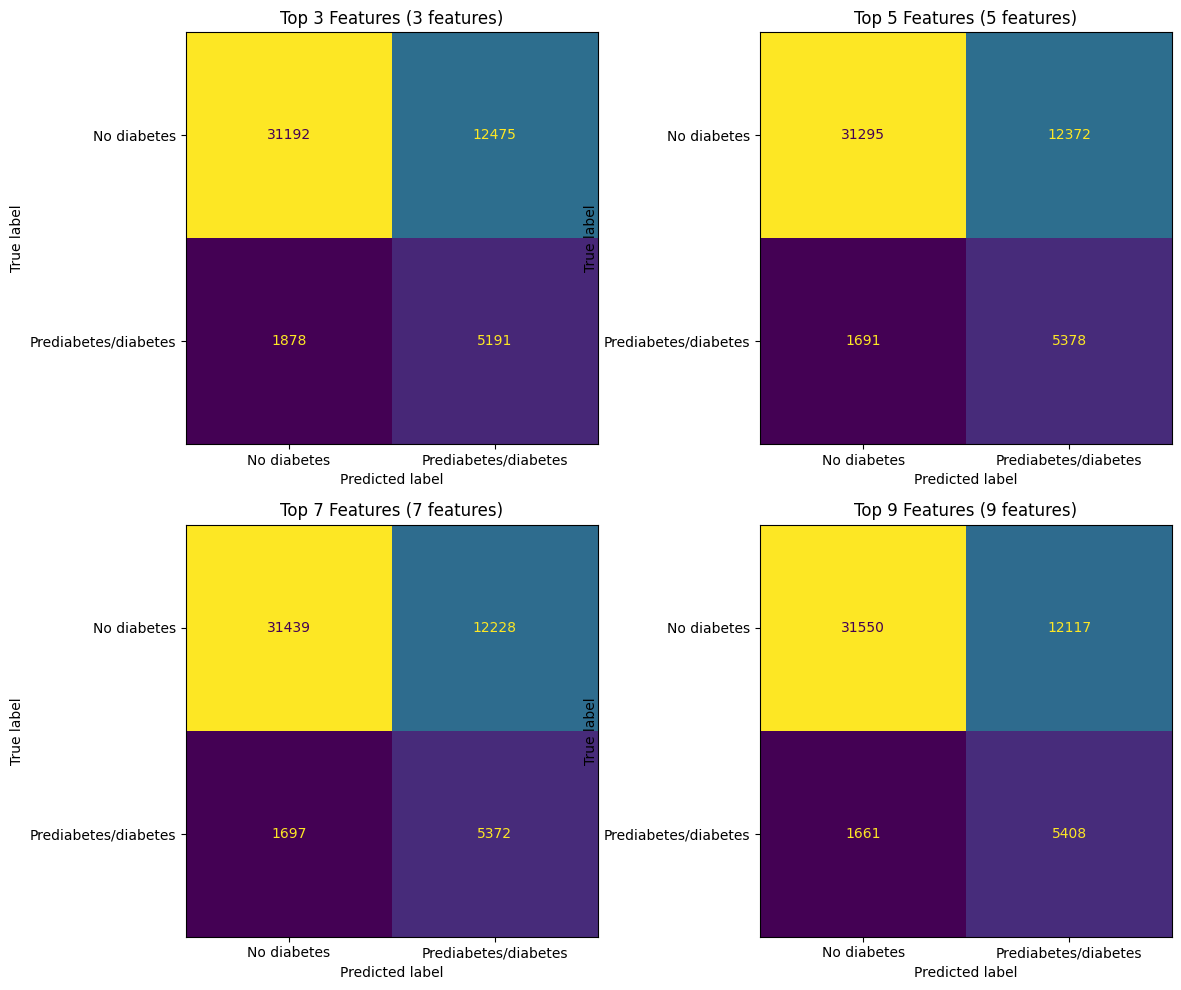

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Features ranked by importance from your original model
ranked_features = [
    "GenHlth",
    "BMI",
    "Age",
    "HighBP",
    "HighChol",
    "CholCheck",
    "HvyAlcoholConsump",
    "Sex",
    "Income"
]

# Create the four feature sets
feature_sets = {
    "Top 3 Features": ranked_features[:3],
    "Top 5 Features": ranked_features[:5],
    "Top 7 Features": ranked_features[:7],
    "Top 9 Features": ranked_features[:9]
}

results = []
predictions_by_model = {}

# Train and evaluate each model
for name, features in feature_sets.items():

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    # Train the model
    model.fit(X_train[features], y_train)

    # Predict class labels
    predictions = model.predict(X_test[features])

    # Predict probabilities for ROC-AUC
    probabilities = model.predict_proba(X_test[features])[:, 1]

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    roc_auc = roc_auc_score(y_test, probabilities)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    predictions_by_model[name] = predictions

    results.append({
        "Model": name,
        "Number of Features": len(features),
        "Precision": precision,
        "Recall": recall,
        "ROC-AUC": roc_auc,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

# Display comparison table
results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

# Display all four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, features) in zip(axes, feature_sets.items()):

    cm = confusion_matrix(
        y_test,
        predictions_by_model[name],
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No diabetes", "Prediabetes/diabetes"]
    )

    display.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{name} ({len(features)} features)")

plt.tight_layout()
plt.show()


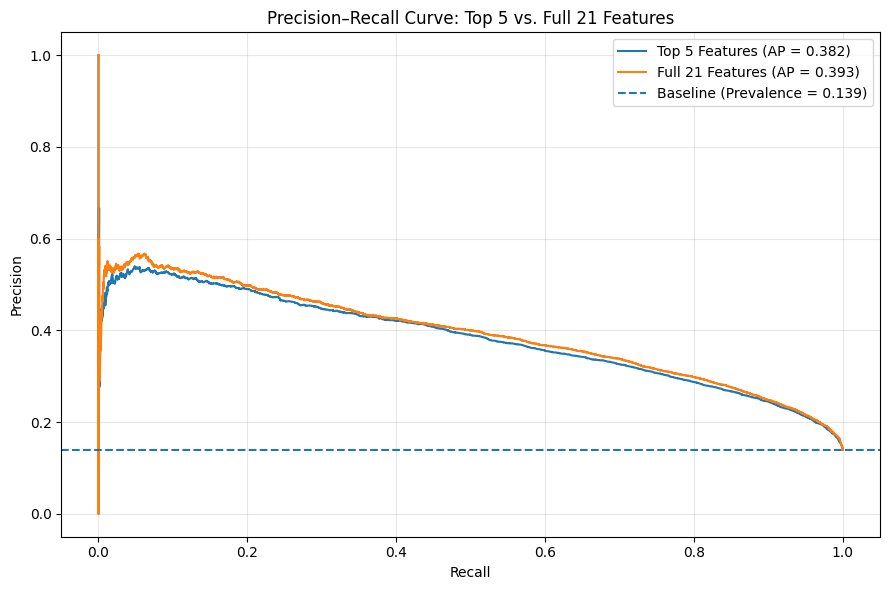

Top 5 Features Average Precision: 0.3823
Full 21 Features Average Precision: 0.3926


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Define the two feature sets
top5_features = [
    "GenHlth",
    "BMI",
    "Age",
    "HighBP",
    "HighChol"
]

all_features = list(X_train.columns)

# Train the top 5 model
top5_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)
top5_model.fit(X_train[top5_features], y_train)

# Train the full 21-feature model
full_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)
full_model.fit(X_train[all_features], y_train)

# Get predicted probabilities for the positive class
top5_probs = top5_model.predict_proba(X_test[top5_features])[:, 1]
full_probs = full_model.predict_proba(X_test[all_features])[:, 1]

# Calculate precision-recall curves
top5_precision, top5_recall, _ = precision_recall_curve(
    y_test, top5_probs
)
full_precision, full_recall, _ = precision_recall_curve(
    y_test, full_probs
)

# Calculate Average Precision (AP)
top5_ap = average_precision_score(y_test, top5_probs)
full_ap = average_precision_score(y_test, full_probs)

# Plot both curves
plt.figure(figsize=(9, 6))

plt.plot(
    top5_recall,
    top5_precision,
    label=f"Top 5 Features (AP = {top5_ap:.3f})"
)

plt.plot(
    full_recall,
    full_precision,
    label=f"Full 21 Features (AP = {full_ap:.3f})"
)

# Baseline: positive-class proportion
baseline = y_test.mean()
plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Baseline (Prevalence = {baseline:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: Top 5 vs. Full 21 Features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Top 5 Features Average Precision: {top5_ap:.4f}")
print(f"Full 21 Features Average Precision: {full_ap:.4f}")
